In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%load_ext sql
%sql duckdb:///project.duckdb

Connecting to 'duckdb:///project.duckdb'

In [2]:
%%sql
CREATE
OR REPLACE TABLE block_table_capri AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_capri/pangenome/pangenome.bi'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [3]:
%%sql
SELECT
  *
FROM
  block_table_capri
LIMIT
  10

Running query in 'duckdb:///project.duckdb'

block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,MYMY1,MYMY11,MYMY13,MYMY16,MYMY18,MYMY20,MYMY22,MYMY24,MYMY28,MYMY3,MYMY30,MYMY32,MYMY34,MYMY36,MYMY42,MYMY5,MYMY7,MYMY9
r99x117,99,117,109,3,5,0,0,0.9444,0.2356,0,8,21,0,4,0,0,0,2,1,0,0,0,0,6,18,21,18
r98x426,98,426,390,0,36,0,0,0.9154,0.299,0,8,21,0,4,0,0,0,1,1,0,0,0,0,6,18,21,18
r98x319,98,319,289,1,29,0,0,0.9075,0.2543,0,8,21,0,4,0,0,0,1,1,0,0,0,0,6,18,21,18
r97x171,97,171,158,0,13,0,0,0.9239,0.2722,0,8,21,0,4,0,0,0,1,0,0,0,0,0,6,18,21,18
r97x101,97,101,93,5,3,0,0,0.9455,0.3703,0,7,21,0,4,0,0,0,1,1,0,0,0,0,6,18,21,18
m97x63,97,63,51,0,12,0,0,0.8095,0.3873,0,8,21,0,4,0,0,0,1,0,0,0,0,0,6,18,21,18
r89x137,89,137,125,1,11,0,0,0.916,0.2317,0,11,11,3,4,0,0,0,0,26,0,0,0,0,9,8,9,8
r89x116,89,116,105,0,10,1,0,0.9051,0.2502,0,11,11,3,4,0,0,0,0,26,0,0,0,0,9,8,9,8
r87x125,87,125,117,1,7,0,0,0.94,0.2165,0,11,11,3,4,0,0,0,0,24,0,0,0,0,9,8,9,8
r86x100,86,100,90,0,10,0,0,0.9,0.2086,0,11,11,3,4,0,0,0,0,26,0,0,0,0,6,8,9,8


### Проверим, является ли кажадая строка в таблице блоков пангенома *Mycoplasma mycoides* subsp *capri* уникальным блоком

In [4]:
%%sql
SELECT
  COUNT(DISTINCT block) AS n_blocks,
  COUNT(*) AS n_rows
FROM
  block_table_capri

Running query in 'duckdb:///project.duckdb'

n_blocks,n_rows
7771,7771


### Соберём основные данные о пангеноме *Mycoplasma mycoides* subsp *capri*, а именно - распределение числа блоков, их процентной доли, их доли длины и среднююю длину

In [58]:
%%sql
    CREATE OR REPLACE TABLE capri_stats AS
SELECT
  LEFT (block, 1) AS prefix,
  COUNT(*) AS n_blocks,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
  ROUND(100.0 * SUM(cols) / SUM(SUM(cols)) OVER (), 2) AS length_percent,
  ROUND(AVG(cols), 1) AS avg_len
FROM
  block_table_capri
GROUP BY
  LEFT (block, 1)
ORDER BY
  length_percent DESC

Running query in 'duckdb:///project.duckdb'

Count


In [60]:
%%sql
SELECT *
FROM capri_stats

Running query in 'duckdb:///project.duckdb'

prefix,n_blocks,pct,length_percent,avg_len
h,2683,34.53,37.26,264.4
s,298,3.83,34.64,2213.4
u,883,11.36,15.58,335.9
r,453,5.83,6.76,284.0
m,3454,44.45,5.77,31.8


### Рассчитаем среднее сходство внутри блоков, как просто среднее, так и среднее взвешенное на длину блока для пангенома *Mycoplasma mycoides* subsp *capri*

In [6]:
%%sql
SELECT
  ROUND(100 * AVG(ident), 2) AS simple_avg,
  ROUND(100.0 * SUM(ident * cols) / SUM(cols), 2) AS weighted_avg
FROM
  block_table_capri

Running query in 'duckdb:///project.duckdb'

simple_avg,weighted_avg
83.85,94.71


### Посмотрим распределение среднего и среднего взвешенного на длину сходства между блоками, разделённого на типы блоков. Пангеном *Mycoplasma mycoides* subsp *capri*

In [7]:
%%sql
SELECT
  LEFT (block, 1) AS block_type,
  ROUND(100 * AVG(ident), 2) AS avg_ident_by_block_type,
  ROUND(100.0 * SUM(ident * cols) / SUM(cols), 2) AS weight_avg_ident_by_block_type
FROM
  block_table_capri
GROUP BY
  LEFT (block, 1)
ORDER BY
  weight_avg_ident_by_block_type DESC

Running query in 'duckdb:///project.duckdb'

block_type,avg_ident_by_block_type,weight_avg_ident_by_block_type
u,100.0,100.0
h,93.5,94.38
s,92.88,94.15
r,93.24,93.99
m,70.23,86.8


In [8]:
%%sql
CREATE
OR REPLACE TABLE block_table_mycoides AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_mycoides/pangenome/pangenome.bi'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [9]:
%%sql
SELECT
  *
FROM
  block_table_mycoides
LIMIT
  10

Running query in 'duckdb:///project.duckdb'

block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,MYMY1,MYMY11,MYMY13,MYMY15,MYMY17,MYMY19,MYMY21,MYMY23,MYMY25,MYMY27,MYMY29,MYMY3,MYMY31,MYMY33,MYMY35,MYMY5,MYMY7,MYMY9
r939x116,939,116,105,6,2,3,0,0.931,0.3119,59,56,55,56,55,55,56,54,45,43,37,56,43,57,45,56,55,56
r930x360,930,360,333,5,22,0,0,0.9319,0.2748,58,56,55,55,54,54,55,53,45,43,37,56,43,56,45,56,54,55
r929x118,929,118,110,4,4,0,0,0.9491,0.2627,59,56,55,56,55,54,53,54,44,43,36,55,42,57,45,55,54,56
m929x8,929,8,5,2,1,0,0,0.75,0.5794,59,56,55,56,55,54,53,54,44,43,36,55,42,57,45,55,54,56
r928x106,928,106,96,2,8,0,0,0.915,0.2489,58,56,55,55,54,54,54,53,45,43,37,56,42,56,45,56,54,55
m928x11,928,11,7,0,4,0,0,0.6363,0.3618,58,56,55,55,54,54,54,53,45,43,37,56,42,56,45,56,54,55
r927x168,927,168,153,5,7,3,0,0.9255,0.2182,58,56,55,55,54,54,54,53,45,43,37,56,43,56,43,56,54,55
r921x106,921,106,96,3,5,2,0,0.9198,0.2405,58,56,55,55,54,54,54,53,45,41,34,56,43,56,42,56,54,55
r918x119,918,119,108,3,7,1,0,0.9201,0.248,57,55,54,53,53,53,55,51,45,43,37,55,43,56,45,55,53,55
m918x101,918,101,71,19,7,4,0,0.797,0.2008,57,55,54,53,53,53,55,51,45,43,37,55,43,56,45,55,53,55


In [10]:
%%sql
SELECT
  COUNT(DISTINCT block) AS n_blocks,
  COUNT(*) AS n_rows
FROM
  block_table_mycoides

Running query in 'duckdb:///project.duckdb'

n_blocks,n_rows
676,676


### Соберём основные данные о пангеноме *Mycoplasma mycoides* subsp *mycoides*, а именно - распределение числа блоков, их процентной доли, их доли длины и среднююю длину

In [55]:
%%sql
    CREATE OR REPLACE TABLE mycoides_stats AS
SELECT
  LEFT (block, 1) AS prefix,
  COUNT(*) AS n_blocks,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
  ROUND(100.0 * SUM(cols) / SUM(SUM(cols)) OVER (), 2) AS length_percent,
  ROUND(AVG(cols), 1) AS avg_len
FROM
  block_table_mycoides
GROUP BY
  LEFT (block, 1)
ORDER BY
  length_percent DESC

Running query in 'duckdb:///project.duckdb'

Count


In [57]:
%%sql
SELECT *
FROM mycoides_stats

Running query in 'duckdb:///project.duckdb'

prefix,n_blocks,pct,length_percent,avg_len
s,125,18.49,84.3,6648.3
r,158,23.37,8.67,541.0
h,56,8.28,5.61,986.9
m,326,48.22,1.28,38.7
u,11,1.63,0.14,127.7


### Рассчитаем среднее сходство внутри блоков, как просто среднее, так и среднее взвешенное на длину блока для пангенома *Mycoplasma mycoides* subsp *mycoides*

In [12]:
%%sql
SELECT
  ROUND(100 * AVG(ident), 2) AS simple_avg,
  ROUND(100.0 * SUM(ident * cols) / SUM(cols), 2) AS weighted_avg
FROM
  block_table_mycoides

Running query in 'duckdb:///project.duckdb'

simple_avg,weighted_avg
94.83,99.61


### Посмотрим распределение среднего и среднего взвешенного на длину сходства между блоками, разделённого на типы блоков. Пангеном *Mycoplasma mycoides* subsp *mycoides*

In [13]:
%%sql
SELECT
  LEFT (block, 1) AS block_type,
  ROUND(100 * AVG(ident), 2) AS avg_ident_by_block_type,
  ROUND(100.0 * SUM(ident * cols) / SUM(cols), 2) AS weight_avg_ident_by_block_type
FROM
  block_table_mycoides
GROUP BY
  LEFT (block, 1)
ORDER BY
  weight_avg_ident_by_block_type DESC

Running query in 'duckdb:///project.duckdb'

block_type,avg_ident_by_block_type,weight_avg_ident_by_block_type
u,100.0,100.0
s,99.68,99.81
h,99.45,99.68
r,95.53,98.15
m,91.66,96.03


In [45]:
%%sql
CREATE
OR REPLACE TABLE block_table_mycoides_95 AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_mycoides_95/pangenome/pangenome.bi'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [47]:
%%sql
SELECT
  COUNT(DISTINCT block) AS n_blocks,
  COUNT(*) AS n_rows
FROM
  block_table_mycoides_95

Running query in 'duckdb:///project.duckdb'

n_blocks,n_rows
895,895


### Соберём основные данные о пангеноме *Mycoplasma mycoides* subsp *mycoides* (95% сходство), а именно - распределение числа блоков, их процентной доли, их доли длины и среднююю длину

In [53]:
%%sql
    CREATE OR REPLACE TABLE mycoides_95_stats AS
SELECT
  LEFT (block, 1) AS prefix,
  COUNT(*) AS n_blocks,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
  ROUND(100.0 * SUM(cols) / SUM(SUM(cols)) OVER (), 2) AS length_percent,
  ROUND(AVG(cols), 1) AS avg_len
FROM
  block_table_mycoides_95
GROUP BY
  LEFT (block, 1)
ORDER BY
  length_percent DESC

Running query in 'duckdb:///project.duckdb'

Count


In [54]:
%%sql
SELECT *
FROM mycoides_95_stats

Running query in 'duckdb:///project.duckdb'

prefix,n_blocks,pct,length_percent,avg_len
s,105,11.73,83.39,7956.0
r,217,24.25,8.99,415.0
h,58,6.48,6.02,1040.3
m,497,55.53,1.37,27.7
u,18,2.01,0.23,126.1


### Сравнение взвешенных долей блоков для всех пангеномов

In [64]:
%%sql
SELECT prefix,
        c.length_percent AS capri_length_percent,
        m.length_percent AS mycoides_length_percent,
        m95.length_percent AS mycoides_95_length_percent
FROM mycoides_95_stats AS m95
        INNER JOIN capri_stats AS c USING (prefix)
        INNER JOIN mycoides_stats AS m USING (prefix)
ORDER BY prefix

Running query in 'duckdb:///project.duckdb'

prefix,capri_length_percent,mycoides_length_percent,mycoides_95_length_percent
h,37.26,5.61,6.02
m,5.77,1.28,1.37
r,6.76,8.67,8.99
s,34.64,84.3,83.39
u,15.58,0.14,0.23


In [14]:
%%sql
CREATE
OR REPLACE TABLE alan_table_capri AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_capri/alan_result/groups.csv'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [15]:
%%sql
SELECT
  *
FROM
  alan_table_capri
LIMIT
  10

Running query in 'duckdb:///project.duckdb'

column00,block,block_type,seq_num,block_len,ori,start,stop,len,core_start,core_stop,core_len,genes_num,is_true_start,is_true_stop,core_%,annotation_loss,wrong_start,"Mycoplasma mycoides subsp. capri strain Ker.TCR. LT chromosome, complete genome","Mycoplasma mycoides subsp. capri strain M-5 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain HN-A chromosome, complete genome","Mycoplasma mycoides subsp. capri strain IVB-X chromosome, complete genome","Mycoplasma mycoides subsp. capri strain My-I chromosome, complete genome","Mycoplasma mycoides subsp. capri strain M-18 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain My-325 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 7730 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 83/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 152/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain PG3 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain G1283.94 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain G1313.94 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain KY230116 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain Wi8079 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 171/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri LC str. 95010 chromosome, complete sequence","Mycoplasma mycoides subsp. capri strain 80/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 152/93 plasmid pMmc_152_93, complete sequence","Mycoplasma mycoides subsp. capri LC str. 95010 plasmid, complete genome"
0,h10x100,h,10,100,-1,1,100,100,1,100,100,10,False,False,100.0,No mistake,No mistake,False,False,True,False,True,False,False,True,True,True,True,False,False,True,True,False,True,True,False,False
1,h10x100n1,h,10,100,-1,1,100,100,1,100,100,10,False,False,100.0,No mistake,No mistake,True,True,True,True,True,True,True,True,False,False,True,False,False,True,False,False,False,False,False,False
2,h10x100n2,h,10,100,-1,1,100,100,1,100,100,10,False,False,100.0,No mistake,No mistake,True,False,False,True,False,False,False,True,True,True,True,False,False,False,True,True,True,True,False,False
3,h10x100n3,h,10,100,1,1,76,76,1,76,76,10,False,True,100.0,No mistake,No mistake,False,True,False,True,True,True,True,True,False,False,True,False,False,True,True,False,False,True,False,False
4,h10x100n3,h,10,100,1,91,100,10,91,100,10,10,True,False,100.0,No mistake,No mistake,False,True,False,True,True,True,True,True,False,False,True,False,False,True,True,False,False,True,False,False
5,h10x101n1,h,10,101,-1,1,101,101,1,101,101,10,False,False,100.0,No mistake,No mistake,False,True,False,False,True,True,True,True,False,True,False,False,False,False,True,True,True,True,False,False
6,h10x101n2,h,10,101,-1,1,101,101,1,101,101,10,False,False,100.0,No mistake,No mistake,False,True,True,True,True,True,True,True,False,True,False,True,True,False,False,False,False,False,False,False
7,h10x101n4,h,10,101,-1,1,101,101,1,101,101,10,False,False,100.0,No mistake,No mistake,True,True,False,False,True,True,True,True,False,True,False,True,True,False,False,False,True,False,False,False
8,h10x101n5,h,10,101,-1,1,101,101,1,101,101,10,False,False,100.0,No mistake,No mistake,False,True,False,True,True,True,True,True,True,False,False,False,False,False,False,True,True,True,False,False
9,h10x102,h,10,102,-1,1,102,102,1,102,102,10,False,False,100.0,No mistake,No mistake,True,True,False,True,True,True,True,False,True,True,True,False,False,False,True,False,False,False,False,False


### Посмотрим на долю пропусков всего одного гена от всех групп с пропущенными генами в пангеноме *Mycoplasma mycoides* subsp *capri*

In [16]:
%%sql
SELECT
  SUM(
    CASE
      WHEN (genes_num - 1 = seq_num)
      AND (is_true_start = TRUE)
      AND (is_true_stop = TRUE) THEN 1
      ELSE 0
    END
  ) AS one_drop,
  SUM(
    CASE
      WHEN (genes_num < seq_num)
      AND (is_true_start = TRUE)
      AND (is_true_stop = TRUE) THEN 1
      ELSE 0
    END
  ) AS any_drop,
  ROUND(
    1.0 * SUM(
      CASE
        WHEN (genes_num - 1 = seq_num)
        AND (is_true_start = TRUE)
        AND (is_true_stop = TRUE) THEN 1
        ELSE 0
      END
    ) / SUM(
      CASE
        WHEN (genes_num < seq_num)
        AND (is_true_start = TRUE)
        AND (is_true_stop = TRUE) THEN 1
        ELSE 0
      END
    ),
    2
  ) AS ratio
FROM
  alan_table_capri

Running query in 'duckdb:///project.duckdb'

one_drop,any_drop,ratio
15,19,0.79


In [17]:
%%sql
CREATE
OR REPLACE TABLE alan_table_mycoides AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_mycoides/alan_result/groups.csv'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [18]:
%%sql
SELECT
  *
FROM
  alan_table_mycoides
LIMIT
  10

Running query in 'duckdb:///project.duckdb'

column00,block,block_type,seq_num,block_len,ori,start,stop,len,core_start,core_stop,core_len,genes_num,is_true_start,is_true_stop,core_%,annotation_loss,wrong_start,"Mycoplasma mycoides subsp. mycoides strain 4378 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain 91130 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain 2059 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain 6364 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain Afade-1 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain Fatick chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain B773-125 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain PO-2 chromosome, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben1, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben326, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben468, complete genome","Mycoplasma mycoides subsp. mycoides SC str. Gladysdale MU clone SC5, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben181, complete genome","Mycoplasma mycoides subsp. mycoides strain izsam_mm5713, complete genome","Mycoplasma mycoides subsp. mycoides strain T1/44, complete genome","Mycoplasma mycoides subsp. mycoides V DNA, complete genome","Mycoplasma mycoides subsp. mycoides SC str. PG1, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben50, complete genome"
0,h13x109,h,13,109,1,1,5,5,1,5,5,13,False,True,100.0,No mistake,No mistake,True,True,True,True,True,True,True,True,True,False,False,True,False,True,True,True,False,False
1,h13x132,h,13,132,1,1,5,5,1,5,5,13,False,True,100.0,No mistake,No mistake,True,True,True,True,True,True,True,True,False,False,False,True,False,True,True,True,True,False
2,h13x146,h,13,146,-1,120,146,27,120,146,27,13,False,True,100.0,No mistake,No mistake,True,True,True,True,True,True,True,True,False,False,False,True,False,True,True,True,True,False
3,h13x147,h,13,147,-1,1,147,147,1,147,147,13,False,False,100.0,No mistake,No mistake,True,True,True,True,True,True,True,True,False,False,False,True,False,True,True,True,True,False
4,h13x155,h,13,155,-1,1,95,95,1,83,83,12,True,False,87.37,No mistake,Wrong start,True,True,True,True,True,True,True,True,False,False,False,True,False,True,True,True,False,False
5,h14x2899,h,14,2899,1,62,214,153,74,214,141,14,True,True,92.16,No mistake,Wrong start,True,True,False,True,True,True,False,False,True,True,True,True,True,False,True,True,True,True
6,h14x2899,h,14,2899,1,265,351,87,265,351,87,1,True,True,100.0,Possible annotation loss,No mistake,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
7,h14x2899,h,14,2899,1,465,2899,2435,2008,2015,8,16,True,False,0.33,No mistake,Wrong start,True,True,False,True,True,True,False,False,True,True,True,True,True,False,True,True,True,True
8,h14x2899,h,14,2899,1,2008,2899,892,2017,2899,883,14,True,False,98.99,No mistake,Wrong start,True,True,False,True,True,True,False,False,True,True,True,True,True,False,True,True,True,True
9,h14x3111,h,14,3111,1,1,688,688,1,148,148,14,False,True,21.51,No mistake,No mistake,True,True,False,True,True,True,False,False,True,True,True,True,True,False,True,True,True,True


### Посмотрим на долю пропусков всего одного гена от всех групп с пропущенными генами в пангеноме *Mycoplasma mycoides* subsp *mycoides*

In [19]:
%%sql
SELECT
  SUM(
    CASE
      WHEN (genes_num - 1 = seq_num)
      AND (is_true_start = TRUE)
      AND (is_true_stop = TRUE) THEN 1
      ELSE 0
    END
  ) AS one_drop,
  SUM(
    CASE
      WHEN (genes_num < seq_num)
      AND (is_true_start = TRUE)
      AND (is_true_stop = TRUE) THEN 1
      ELSE 0
    END
  ) AS any_drop,
  ROUND(
    1.0 * SUM(
      CASE
        WHEN (genes_num - 1 = seq_num)
        AND (is_true_start = TRUE)
        AND (is_true_stop = TRUE) THEN 1
        ELSE 0
      END
    ) / SUM(
      CASE
        WHEN (genes_num < seq_num)
        AND (is_true_start = TRUE)
        AND (is_true_stop = TRUE) THEN 1
        ELSE 0
      END
    ),
    2
  ) AS ratio
FROM
  alan_table_mycoides

Running query in 'duckdb:///project.duckdb'

one_drop,any_drop,ratio
31,140,0.22


In [20]:
alan_table_capri = pd.read_csv("mycoplasma_mycoides_subsp_capri/alan_result/groups.csv", index_col = 0)
alan_table_capri.head(10)

,block,block_type,seq_num,block_len,ori,start,stop,len,core_start,core_stop,...,"Mycoplasma mycoides subsp. capri strain PG3 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain G1283.94 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain G1313.94 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain KY230116 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain Wi8079 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 171/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri LC str. 95010 chromosome, complete sequence","Mycoplasma mycoides subsp. capri strain 80/93 chromosome, complete genome","Mycoplasma mycoides subsp. capri strain 152/93 plasmid pMmc_152_93, complete sequence","Mycoplasma mycoides subsp. capri LC str. 95010 plasmid, complete genome"
0,h10x100,h,10,100,-1,1,100,100,1,100,...,True,False,False,True,True,False,True,True,False,False
1,h10x100n1,h,10,100,-1,1,100,100,1,100,...,True,False,False,True,False,False,False,False,False,False
2,h10x100n2,h,10,100,-1,1,100,100,1,100,...,True,False,False,False,True,True,True,True,False,False
3,h10x100n3,h,10,100,1,1,76,76,1,76,...,True,False,False,True,True,False,False,True,False,False
4,h10x100n3,h,10,100,1,91,100,10,91,100,...,True,False,False,True,True,False,False,True,False,False
5,h10x101n1,h,10,101,-1,1,101,101,1,101,...,False,False,False,False,True,True,True,True,False,False
6,h10x101n2,h,10,101,-1,1,101,101,1,101,...,False,True,True,False,False,False,False,False,False,False
7,h10x101n4,h,10,101,-1,1,101,101,1,101,...,False,True,True,False,False,False,True,False,False,False
8,h10x101n5,h,10,101,-1,1,101,101,1,101,...,False,False,False,False,False,True,True,True,False,False
9,h10x102,h,10,102,-1,1,102,102,1,102,...,True,False,False,False,True,False,False,False,False,False


### Построим распределение геномов по числу групп с пропусками, где они отсутствуют в пангеноме *Mycoplasma mycoides* subsp *capri*

In [21]:
filter_capri = (alan_table_capri["genes_num"] < alan_table_capri["seq_num"]) & (alan_table_capri["is_true_start"]) & (alan_table_capri["is_true_stop"])
(alan_table_capri[filter_capri].iloc[:, 16:] == False).sum().sort_values(ascending = False)

Mycoplasma mycoides subsp. capri LC str. 95010 plasmid, complete genome                  19
Mycoplasma mycoides subsp. capri strain 152/93 plasmid pMmc_152_93, complete sequence    19
Mycoplasma mycoides subsp. capri LC str. 95010 chromosome, complete sequence             17
Mycoplasma mycoides subsp. capri strain Wi8079 chromosome, complete genome               13
Mycoplasma mycoides subsp. capri strain 83/93 chromosome, complete genome                13
Mycoplasma mycoides subsp. capri strain PG3 chromosome, complete genome                  13
Mycoplasma mycoides subsp. capri strain 80/93 chromosome, complete genome                12
Mycoplasma mycoides subsp. capri strain 171/93 chromosome, complete genome               12
Mycoplasma mycoides subsp. capri strain Ker.TCR. LT chromosome, complete genome          12
Mycoplasma mycoides subsp. capri strain KY230116 chromosome, complete genome             12
Mycoplasma mycoides subsp. capri strain IVB-X chromosome, complete genome       

In [22]:
block_table_capri = pd.read_csv("mycoplasma_mycoides_subsp_capri/pangenome/pangenome.bi", sep = "\t")
block_table_capri

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY28,MYMY3,MYMY30,MYMY32,MYMY34,MYMY36,MYMY42,MYMY5,MYMY7,MYMY9
0,r99x117,99,117,109,3,5,0,0,0.9444,0.2356,...,2,1,0,0,0,0,6,18,21,18
1,r98x426,98,426,390,0,36,0,0,0.9154,0.2990,...,1,1,0,0,0,0,6,18,21,18
2,r98x319,98,319,289,1,29,0,0,0.9075,0.2543,...,1,1,0,0,0,0,6,18,21,18
3,r97x171,97,171,158,0,13,0,0,0.9239,0.2722,...,1,0,0,0,0,0,6,18,21,18
4,r97x101,97,101,93,5,3,0,0,0.9455,0.3703,...,1,1,0,0,0,0,6,18,21,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7766,m1x1n55,1,1,1,0,0,0,0,1.0000,1.0000,...,0,0,0,0,0,0,1,0,0,0
7767,m1x1n6,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,1,0,0,0
7768,m1x1n7,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,0
7769,m1x1n8,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,0


In [23]:
block_table_capri["block_type"] = block_table_capri["block"].str[0]
block_table_capri

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY3,MYMY30,MYMY32,MYMY34,MYMY36,MYMY42,MYMY5,MYMY7,MYMY9,block_type
0,r99x117,99,117,109,3,5,0,0,0.9444,0.2356,...,1,0,0,0,0,6,18,21,18,r
1,r98x426,98,426,390,0,36,0,0,0.9154,0.2990,...,1,0,0,0,0,6,18,21,18,r
2,r98x319,98,319,289,1,29,0,0,0.9075,0.2543,...,1,0,0,0,0,6,18,21,18,r
3,r97x171,97,171,158,0,13,0,0,0.9239,0.2722,...,0,0,0,0,0,6,18,21,18,r
4,r97x101,97,101,93,5,3,0,0,0.9455,0.3703,...,1,0,0,0,0,6,18,21,18,r
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7766,m1x1n55,1,1,1,0,0,0,0,1.0000,1.0000,...,0,0,0,0,0,1,0,0,0,m
7767,m1x1n6,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,1,0,0,0,m
7768,m1x1n7,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,m
7769,m1x1n8,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,m


### Гистограмма распределения числа h-блоков по числу последовательностей в них. Пангеном *Mycoplasma mycoides* subsp *capri*

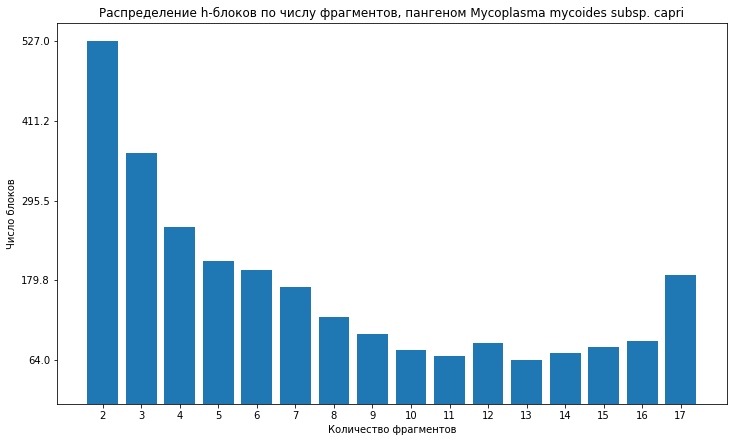

In [81]:
fig, ax1 = plt.subplots(figsize = (12, 7))
col = block_table_capri["fragments"][block_table_capri["block_type"] == "h"]
b = col.value_counts()
plt.bar(b.index, b.values)
plt.xticks(range(min(col), max(col) + 1))
plt.yticks(np.linspace(min(b), max(b), 5))
ax1.set_xlabel("Количество фрагментов")
ax1.set_ylabel("Число блоков")
ax1.set_title("Распределение h-блоков по числу фрагментов, пангеном Mycoplasma mycoides subsp. capri")
plt.show()

In [25]:
alan_table_mycoides = pd.read_csv("mycoplasma_mycoides_subsp_mycoides/alan_result/groups.csv", index_col = 0)
alan_table_mycoides.head(10)

,block,block_type,seq_num,block_len,ori,start,stop,len,core_start,core_stop,...,"Mycoplasma mycoides subsp. mycoides strain Ben1, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben326, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben468, complete genome","Mycoplasma mycoides subsp. mycoides SC str. Gladysdale MU clone SC5, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben181, complete genome","Mycoplasma mycoides subsp. mycoides strain izsam_mm5713, complete genome","Mycoplasma mycoides subsp. mycoides strain T1/44, complete genome","Mycoplasma mycoides subsp. mycoides V DNA, complete genome","Mycoplasma mycoides subsp. mycoides SC str. PG1, complete genome","Mycoplasma mycoides subsp. mycoides strain Ben50, complete genome"
0,h13x109,h,13,109,1,1,5,5,1,5,...,True,False,False,True,False,True,True,True,False,False
1,h13x132,h,13,132,1,1,5,5,1,5,...,False,False,False,True,False,True,True,True,True,False
2,h13x146,h,13,146,-1,120,146,27,120,146,...,False,False,False,True,False,True,True,True,True,False
3,h13x147,h,13,147,-1,1,147,147,1,147,...,False,False,False,True,False,True,True,True,True,False
4,h13x155,h,13,155,-1,1,95,95,1,83,...,False,False,False,True,False,True,True,True,False,False
5,h14x2899,h,14,2899,1,62,214,153,74,214,...,True,True,True,True,True,False,True,True,True,True
6,h14x2899,h,14,2899,1,265,351,87,265,351,...,False,False,False,True,False,False,False,False,False,False
7,h14x2899,h,14,2899,1,465,2899,2435,2008,2015,...,True,True,True,True,True,False,True,True,True,True
8,h14x2899,h,14,2899,1,2008,2899,892,2017,2899,...,True,True,True,True,True,False,True,True,True,True
9,h14x3111,h,14,3111,1,1,688,688,1,148,...,True,True,True,True,True,False,True,True,True,True


### Построим распределение геномов по числу групп с пропусками, где они отсутствуют в пангеноме *Mycoplasma mycoides* subsp *mycoides*

In [26]:
filter_mycoides = (alan_table_mycoides["genes_num"] < alan_table_mycoides["seq_num"]) & (alan_table_mycoides["is_true_start"]) & (alan_table_mycoides["is_true_stop"])
(alan_table_mycoides[filter_mycoides].iloc[:, 16:] == False).sum().sort_values(ascending = False)

Mycoplasma mycoides subsp. mycoides strain Ben468, complete genome                      87
Mycoplasma mycoides subsp. mycoides strain Ben1, complete genome                        84
Mycoplasma mycoides subsp. mycoides strain Ben326, complete genome                      82
Mycoplasma mycoides subsp. mycoides strain Ben181, complete genome                      77
Mycoplasma mycoides subsp. mycoides strain Ben50, complete genome                       76
Mycoplasma mycoides subsp. mycoides SC str. PG1, complete genome                        58
Mycoplasma mycoides subsp. mycoides strain izsam_mm5713, complete genome                56
Mycoplasma mycoides subsp. mycoides strain T1/44, complete genome                       51
Mycoplasma mycoides subsp. mycoides strain Fatick chromosome, complete genome           48
Mycoplasma mycoides subsp. mycoides SC str. Gladysdale MU clone SC5, complete genome    48
Mycoplasma mycoides subsp. mycoides strain Afade-1 chromosome, complete genome          47

In [27]:
block_table_mycoides = pd.read_csv("mycoplasma_mycoides_subsp_mycoides/pangenome/pangenome.bi", sep = "\t")
block_table_mycoides

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY25,MYMY27,MYMY29,MYMY3,MYMY31,MYMY33,MYMY35,MYMY5,MYMY7,MYMY9
0,r939x116,939,116,105,6,2,3,0,0.9310,0.3119,...,45,43,37,56,43,57,45,56,55,56
1,r930x360,930,360,333,5,22,0,0,0.9319,0.2748,...,45,43,37,56,43,56,45,56,54,55
2,r929x118,929,118,110,4,4,0,0,0.9491,0.2627,...,44,43,36,55,42,57,45,55,54,56
3,m929x8,929,8,5,2,1,0,0,0.7500,0.5794,...,44,43,36,55,42,57,45,55,54,56
4,r928x106,928,106,96,2,8,0,0,0.9150,0.2489,...,45,43,37,56,42,56,45,56,54,55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,m1x1n5,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,1,0,0,0,0,0
672,m1x1n6,1,1,1,0,0,0,0,1.0000,0.0000,...,0,1,0,0,0,0,0,0,0,0
673,m1x1n7,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,0
674,m1x1n8,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,1,0,0,0,0,0,0,0


In [28]:
block_table_mycoides["block_type"] = block_table_mycoides["block"].str[0]
block_table_mycoides

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY27,MYMY29,MYMY3,MYMY31,MYMY33,MYMY35,MYMY5,MYMY7,MYMY9,block_type
0,r939x116,939,116,105,6,2,3,0,0.9310,0.3119,...,43,37,56,43,57,45,56,55,56,r
1,r930x360,930,360,333,5,22,0,0,0.9319,0.2748,...,43,37,56,43,56,45,56,54,55,r
2,r929x118,929,118,110,4,4,0,0,0.9491,0.2627,...,43,36,55,42,57,45,55,54,56,r
3,m929x8,929,8,5,2,1,0,0,0.7500,0.5794,...,43,36,55,42,57,45,55,54,56,m
4,r928x106,928,106,96,2,8,0,0,0.9150,0.2489,...,43,37,56,42,56,45,56,54,55,r
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,m1x1n5,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,1,0,0,0,0,0,m
672,m1x1n6,1,1,1,0,0,0,0,1.0000,0.0000,...,1,0,0,0,0,0,0,0,0,m
673,m1x1n7,1,1,1,0,0,0,0,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,m
674,m1x1n8,1,1,1,0,0,0,0,1.0000,0.0000,...,0,1,0,0,0,0,0,0,0,m


### Гистограмма распределения числа h-блоков по числу последовательностей в них. Пангеном *Mycoplasma mycoides* subsp *mycoides*

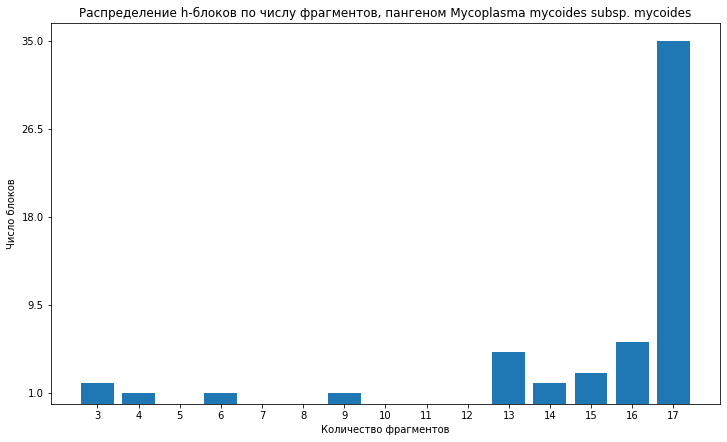

In [80]:
fig, ax1 = plt.subplots(figsize = (12, 7))
col = block_table_mycoides["fragments"][block_table_mycoides["block_type"] == "h"]
b = col.value_counts()
plt.bar(b.index, b.values)
plt.xticks(range(min(col), max(col) + 1))
plt.yticks(np.linspace(min(b), max(b), 5))
ax1.set_xlabel("Количество фрагментов")
ax1.set_ylabel("Число блоков")
ax1.set_title("Распределение h-блоков по числу фрагментов, пангеном Mycoplasma mycoides subsp. mycoides")
plt.show()

In [65]:
block_table_mycoides_95 = pd.read_csv("mycoplasma_mycoides_subsp_mycoides_95/pangenome/pangenome.bi", sep = "\t")
block_table_mycoides_95.head(10)

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY25,MYMY27,MYMY29,MYMY3,MYMY31,MYMY33,MYMY35,MYMY5,MYMY7,MYMY9
0,r932x108,932,108,103,1,4,0,0,0.9583,0.3087,...,45,43,36,56,43,57,45,56,55,56
1,r930x130,930,130,125,0,5,0,0,0.9615,0.2999,...,45,43,37,56,43,56,45,56,54,55
2,r926x117,926,117,112,1,3,1,0,0.9615,0.2221,...,45,43,37,56,43,56,43,56,54,55
3,r889x140,889,140,136,2,2,0,0,0.9785,0.2393,...,45,43,37,53,42,53,45,53,51,52
4,m889x57,889,57,50,1,6,0,0,0.8859,0.3364,...,45,43,37,53,42,53,45,53,51,52
5,r860x106,860,106,101,2,3,0,0,0.9622,0.2491,...,45,43,37,51,42,51,45,51,49,50
6,m860x13,860,13,9,0,4,0,0,0.6923,0.3819,...,45,43,37,51,42,51,45,51,49,50
7,r735x101,735,101,96,1,2,2,0,0.9554,0.2283,...,36,33,29,45,32,46,33,45,44,48
8,r631x105,631,105,100,2,3,0,0,0.9619,0.2623,...,24,18,22,42,24,36,44,40,37,37
9,r467x110,467,110,105,1,4,0,0,0.9590,0.2361,...,32,28,26,25,28,25,27,25,25,25


In [66]:
block_table_mycoides_95["block_type"] = block_table_mycoides_95["block"].str[0]
block_table_mycoides_95.head(10)

,block,fragments,cols,ident-nogap,ident-gap,noident-nogap,noident-gap,pure-gap,ident,GC,...,MYMY27,MYMY29,MYMY3,MYMY31,MYMY33,MYMY35,MYMY5,MYMY7,MYMY9,block_type
0,r932x108,932,108,103,1,4,0,0,0.9583,0.3087,...,43,36,56,43,57,45,56,55,56,r
1,r930x130,930,130,125,0,5,0,0,0.9615,0.2999,...,43,37,56,43,56,45,56,54,55,r
2,r926x117,926,117,112,1,3,1,0,0.9615,0.2221,...,43,37,56,43,56,43,56,54,55,r
3,r889x140,889,140,136,2,2,0,0,0.9785,0.2393,...,43,37,53,42,53,45,53,51,52,r
4,m889x57,889,57,50,1,6,0,0,0.8859,0.3364,...,43,37,53,42,53,45,53,51,52,m
5,r860x106,860,106,101,2,3,0,0,0.9622,0.2491,...,43,37,51,42,51,45,51,49,50,r
6,m860x13,860,13,9,0,4,0,0,0.6923,0.3819,...,43,37,51,42,51,45,51,49,50,m
7,r735x101,735,101,96,1,2,2,0,0.9554,0.2283,...,33,29,45,32,46,33,45,44,48,r
8,r631x105,631,105,100,2,3,0,0,0.9619,0.2623,...,18,22,42,24,36,44,40,37,37,r
9,r467x110,467,110,105,1,4,0,0,0.9590,0.2361,...,28,26,25,28,25,27,25,25,25,r


### Гистограмма распределения числа h-блоков по числу последовательностей в них. Пангеном *Mycoplasma mycoides* subsp *mycoides* (95% сходство)

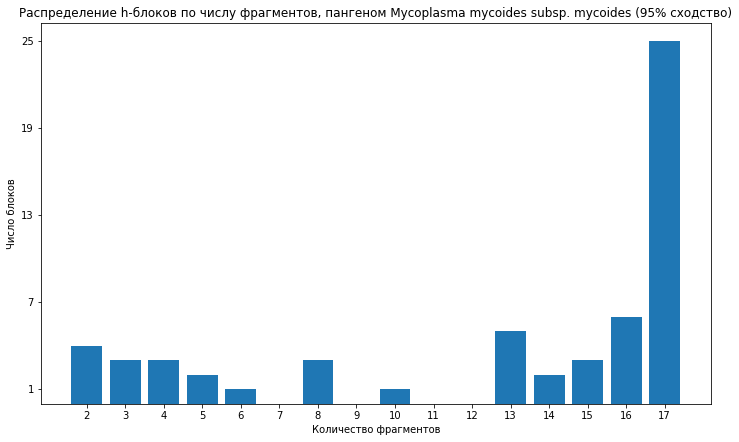

In [79]:
fig, ax1 = plt.subplots(figsize = (12, 7))
col = block_table_mycoides_95["fragments"][block_table_mycoides_95["block_type"] == "h"]
b = col.value_counts()
plt.bar(b.index, b.values)
plt.xticks(range(min(col), max(col) + 1))
plt.yticks(np.linspace(min(b), max(b), 5))
ax1.set_xlabel("Количество фрагментов")
ax1.set_ylabel("Число блоков")
ax1.set_title("Распределение h-блоков по числу фрагментов, пангеном Mycoplasma mycoides subsp. mycoides (95% сходство)")
plt.show()

In [35]:
%%sql
    CREATE OR REPLACE TABLE capri_annotation AS
SELECT annotation_loss,
        COUNT(*) as num
FROM alan_table_capri
GROUP BY annotation_loss
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


### Количество групп с ошибками аннотации в пангеноме *Mycoplasma mycoides* subsp *capri*

In [36]:
%%sql
SELECT *
FROM capri_annotation

Running query in 'duckdb:///project.duckdb'

annotation_loss,num
Possible annotation loss,8
Annotation loss,11
No mistake,7463


In [37]:
%%sql
    CREATE OR REPLACE TABLE capri_start AS
SELECT wrong_start,
        COUNT(*) as num
FROM alan_table_capri
GROUP BY wrong_start
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


In [38]:
%%sql
SELECT *
FROM capri_start

Running query in 'duckdb:///project.duckdb'

wrong_start,num
Possible wrong start,180
Wrong start,259
No mistake,7043


In [39]:
%%sql
    CREATE OR REPLACE TABLE mycoides_annotation AS
SELECT annotation_loss,
        COUNT(*) as num
FROM alan_table_mycoides
GROUP BY annotation_loss
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


### Количество групп с ошибками аннотации в пангеноме *Mycoplasma mycoides* subsp *mycoides*

In [40]:
%%sql
SELECT *
FROM mycoides_annotation

Running query in 'duckdb:///project.duckdb'

annotation_loss,num
Possible annotation loss,53
Annotation loss,87
No mistake,1326


In [41]:
%%sql
    CREATE OR REPLACE TABLE mycoides_start AS
SELECT wrong_start,
        COUNT(*) as num
FROM alan_table_mycoides
GROUP BY wrong_start
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


In [42]:
%%sql
SELECT *
FROM mycoides_start

Running query in 'duckdb:///project.duckdb'

wrong_start,num
Possible wrong start,121
Wrong start,447
No mistake,898


In [70]:
%%sql
CREATE
OR REPLACE TABLE alan_table_mycoides_95 AS
SELECT
  *
FROM
  read_csv (
    'mycoplasma_mycoides_subsp_mycoides_95/alan_result/groups.csv'
  )

Running query in 'duckdb:///project.duckdb'

Count


In [71]:
%%sql
    CREATE OR REPLACE TABLE mycoides_95_annotation AS
SELECT annotation_loss,
        COUNT(*) as num
FROM alan_table_mycoides_95
GROUP BY annotation_loss
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


### Количество групп с ошибками аннотации в пангеноме *Mycoplasma mycoides* subsp *mycoides* (95% сходство)

In [72]:
%%sql
SELECT *
FROM mycoides_95_annotation

Running query in 'duckdb:///project.duckdb'

annotation_loss,num
Possible annotation loss,57
Annotation loss,90
No mistake,1510


In [73]:
%%sql
    CREATE OR REPLACE TABLE mycoides_95_start AS
SELECT wrong_start,
        COUNT(*) as num
FROM alan_table_mycoides_95
GROUP BY wrong_start
ORDER BY num

Running query in 'duckdb:///project.duckdb'

Count


In [74]:
%%sql
SELECT *
FROM mycoides_95_start

Running query in 'duckdb:///project.duckdb'

wrong_start,num
Possible wrong start,130
Wrong start,477
No mistake,1050


### Сравнение числа ошибок во всех пангеномах

In [76]:
%%sql
SELECT
  annotation_loss,
    c.num AS capri_num,
  m.num AS mycoides_num,
    m95.num AS mycoides_95_num
FROM
  mycoides_annotation AS m
  INNER JOIN capri_annotation AS c USING (annotation_loss)
    INNER JOIN mycoides_95_annotation AS m95 USING (annotation_loss)

Running query in 'duckdb:///project.duckdb'

annotation_loss,capri_num,mycoides_num,mycoides_95_num
Possible annotation loss,8,53,57
Annotation loss,11,87,90
No mistake,7463,1326,1510


In [77]:
%%sql
SELECT
  wrong_start,
    c.num AS capri_num,
  m.num AS mycoides_num,
  m95.num AS mycoides_95_num
FROM
  mycoides_start AS m
  INNER JOIN capri_start AS c USING (wrong_start)
    INNER JOIN mycoides_95_start AS m95 USING (wrong_start)

Running query in 'duckdb:///project.duckdb'

wrong_start,capri_num,mycoides_num,mycoides_95_num
Possible wrong start,180,121,130
Wrong start,259,447,477
No mistake,7043,898,1050
